# 03.4 - Multiplex SSB from scratch, at $10^6\ e/\mathrm{\AA}^2$

One notebook, one algorithm, one read. Nothing that matters is behind an import: the
aperture, the SSB kernel, the inversion and the readout are all written out below. The
only things imported are data loading, interlacing and the Poisson draw.

The algorithm is a **$\Gamma$-matched, band-limited inversion of the carrier channel**. It
replaces the repo's `method_wrappers.direct_ssb`, which at $10^6$ returns noise
($\rho = 0.16$, amplitude 5$\times$ too small). This one returns $\rho = 0.80$ with the
amplitude correct to 3%.

---

## 1. The forward model

A weak phase object $O(\mathbf r) = e^{i\varphi(\mathbf r)} \approx 1 + i\varphi$, probed by
an aperture $\tilde A(\mathbf k) = A(\mathbf k)\,e^{-i\chi(\mathbf k)}$ scanned to position
$\mathbf R$. The exit wave is $O(\mathbf r)P(\mathbf r - \mathbf R)$ and the detector sees

$$\Psi_{\mathbf R}(\mathbf k) = \int \tilde O(\mathbf k - \mathbf k')\,
\tilde A(\mathbf k')\,e^{-2\pi i \mathbf k'\cdot\mathbf R}\,d\mathbf k',
\qquad \tilde O(\mathbf q) = \delta(\mathbf q) + i\tilde\varphi(\mathbf q)$$

$I = |\Psi|^2$. Keeping first order in $\varphi$ and taking the **partial Fourier transform
over the scan coordinate only**, $G(\mathbf Q, \mathbf k) = \sum_{\mathbf R} I(\mathbf R,\mathbf k)\,
e^{-2\pi i\mathbf Q\cdot\mathbf R}$, the two cross terms pick out
$\mathbf k' = \mathbf k - \mathbf Q$ and $\mathbf k' = \mathbf k + \mathbf Q$ respectively,
and (using $\tilde\varphi^{*}(-\mathbf Q) = \tilde\varphi(\mathbf Q)$ for real $\varphi$)
collapse to a single term:

$$\boxed{\;G(\mathbf Q, \mathbf k) \;=\; i\,\tilde\varphi(\mathbf Q)\;\Gamma(\mathbf k, \mathbf Q)
\;+\;|A(\mathbf k)|^2\,\delta(\mathbf Q)\;}$$

$$\Gamma(\mathbf k,\mathbf Q) \;\equiv\;
\tilde A^{*}(\mathbf k)\tilde A(\mathbf k - \mathbf Q)\;-\;
\tilde A(\mathbf k)\tilde A^{*}(\mathbf k + \mathbf Q)$$

**This is the whole of SSB.** For each object frequency $\mathbf Q$ the measurement is the
unknown $\tilde\varphi(\mathbf Q)$ multiplied by a known kernel $\Gamma$, read out
simultaneously at every detector pixel $\mathbf k$. It is one scalar unknown per
$\mathbf Q$ and $N_{\rm BF}$ linear measurements of it.

$\Gamma$ has a simple shape. Here $\chi = 0$, so $\tilde A = A$ is real and

$$\Gamma(\mathbf k, \mathbf Q) = A(\mathbf k)\bigl[A(\mathbf k - \mathbf Q) - A(\mathbf k + \mathbf Q)\bigr]$$

which is $+1$ where the direct disc overlaps the $-\mathbf Q$ disc but **not** the
$+\mathbf Q$ one, $-1$ on the mirror crescent, and **exactly 0** elsewhere - including the
triple-overlap centre, where the two terms cancel. Those crescents are the *trotters*. Two
consequences to carry forward:

* $\Gamma(\mathbf k, \mathbf 0) \equiv 0$. The mean of $\varphi$ is **not measurable** by
  SSB, at any dose. Not a noise problem - there is no signal.
* As $|\mathbf Q| \to 0$ the crescents thin to nothing, so $\sum_k|\Gamma|^2 \to 0$ and the
  inversion is increasingly ill-conditioned at exactly the low frequencies our excitation
  lives at.

## 2. The carrier

The acquisition interlaces light-on and light-off on a checkerboard, so

$$I_{\rm merged}(i,j,\mathbf k) = I_0(i,j,\mathbf k) + (-1)^{i+j}\,\Delta I(i,j,\mathbf k),
\qquad \Delta I = \tfrac12\bigl(I_{\rm on} - I_{\rm off}\bigr)$$

$(-1)^{i+j}$ is a carrier at the scan Nyquist, and multiplying by it in real space is a
**roll by $N/2$ in both scan-frequency axes** - exact for even $N$, not an approximation.
So one partial Fourier transform gives both channels for free: $G$ as it stands is the
structural channel, and $G$ rolled by $(N/2, N/2)$ is the differential one. Everything
after this point is applied to both.

## 3. The inversion, and where the repo loses the amplitude

The repo forms $\hat O(\mathbf Q) = \frac{1}{N_{\rm BF}}\sum_k \frac{\Gamma}{|\Gamma|}\,G$.
The phase-only kernel is already exactly zero off the trotters, so this adds no extra noise
- but it divides by $N_{\rm BF}$ when only a fraction of those pixels contributed. Its
transfer function is therefore

$$f(\mathbf Q) \;=\; \frac{1}{N_{\rm BF}}\sum_{\mathbf k}|\Gamma(\mathbf k,\mathbf Q)|
\;=\; \frac{\text{trotter area}}{\text{BF disc area}}$$

which is **0.07 at $|Q| = 0.03\ \mathrm{\AA^{-1}}$, 0.20 at 0.10, and peaks at 0.80 near
0.55**. It is a band-pass that suppresses the signal band by 3-14$\times$ while passing the
signal-free mid-band at nearly unity. That is the entire amplitude deficit, and at finite
dose it is why the output is mid-band noise.

The least-squares / Wiener solution of $G = i\tilde\varphi\,\Gamma$ weights by $\Gamma$
instead of normalising it away, and divides by what actually contributed:

$$\boxed{\;\hat O(\mathbf Q) \;=\;
\frac{\sum_{\mathbf k}\Gamma^{*}(\mathbf k,\mathbf Q)\,G(\mathbf Q,\mathbf k)}
{\sum_{\mathbf k}\bigl|\Gamma(\mathbf k,\mathbf Q)\bigr|^{2} \;+\; \lambda}\;}$$

With $\lambda \to 0$ this is exactly $i\tilde\varphi(\mathbf Q)$. $\lambda$ is a ridge term
that keeps the $|Q|\to 0$ limit finite.

**$\lambda$ alone is not enough.** It is a scalar floor; what the noise needs is a cutoff.
So the second half of the fix is a hard band limit $|\mathbf Q| < Q_{\max}$, justified by
the physics the proposal already argues: excitation-induced charge redistribution is
spatially smoother than the static potential. Measured on this $\Delta\varphi$, 95% of its
energy is below $0.15\ \mathrm{\AA^{-1}}$.

The two fixes are **independent and both needed**, and the notebook below shows all four
corners of that: the band limit buys the shape, the $\Gamma$ weighting buys the amplitude.

## 4. The readout

$\hat O$ is the first-order part of the object transform, so $\mathcal F^{-1}[\hat O]$ is
the complex object. Two of them: $\bar O$ from the structural channel and $\mathrm dO$ from
the carrier channel. Since $\mathrm dO$ came from $\Delta I$, which carries *half* the
difference,

$$\Delta\varphi \;=\; 2\,\mathrm{Im}\!\left(\frac{\mathrm dO}{\bar O}\right)
\;\;\approx\;\; 2\arctan\mathrm{Im}\!\left(\frac{\mathrm dO}{\bar O}\right)$$

Both are used below; they agree to six figures, because $\bar O$'s DC is pinned so
$|\bar O| \equiv 1$ to within the phase excursion.


In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import map_coordinates

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
RESULTS_DIR = NOTEBOOK_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(NOTEBOOK_DIR.parent))

# The ONLY things imported: loading, interlacing, the Poisson draw. No SSB machinery.
import method_wrappers as mw

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- the two knobs -------------------------------------------------------------
DOSE = 1e6          # e/A^2.  None = noiseless
SEED = 0            # pin the Poisson draw so the numbers below are reproducible
# ---------------------------------------------------------------------------------

with open(DATA_DIR / "focus0_geometry.json") as handle:
    META = json.load(handle)

LAM        = META["beam"]["wavelength_ang"]                   # A
ALPHA_MRAD = META["beam"]["convergence_semiangle_mrad"]
C10        = META["beam"]["defocus_C10_ang"]
scan_step  = META["scan"]["step_ang"]                         # A
n_scan     = META["scan"]["n_positions_per_side"]
n_det      = META["detector"]["n_pixels_binned"]

assert C10 == 0.0, "this notebook assumes chi = 0; Gamma below is the real-aperture form"

print(f"{META['beam']['accelerating_voltage_eV']/1e3:.0f} kV, lambda {LAM:.6f} A, "
      f"alpha {ALPHA_MRAD} mrad, C10 {C10} A")
print(f"scan {n_scan}^2 at {scan_step} A over {META['scan']['extent_ang']} A, "
      f"detector {n_det}^2")
print(f"dose {DOSE}  ->  "
      f"{'noiseless' if DOSE is None else f'{DOSE*scan_step**2:,.0f} e per position'}")


cuda:0
60 kV, lambda 0.048661 A, alpha 30.0 mrad, C10 0.0 A
scan 200^2 at 0.15 A over 30.0 A, detector 192^2
dose 1000000.0  ->  22,500 e per position


## Step 0 - the interlaced, dosed datacube

Interlace noiseless, then dose. Each scan position is an independent Poisson draw, so this
is identical to dosing each state first and interlacing afterwards, and it keeps one cube
in memory instead of three.


In [2]:
t0 = time.time()
cube = mw.interlace_scans(np.load(DATA_DIR / "focus0_base_noiseless.npy", mmap_mode="r"),
                          np.load(DATA_DIR / "focus0_excited_noiseless.npy", mmap_mode="r"))
cube = mw.apply_poisson_dose(cube, DOSE, scan_step, seed=SEED)
print(f"cube {cube.shape}  {cube.nbytes/1e9:.1f} GB  ({time.time()-t0:.0f} s)")
print(f"pattern sums {cube.sum(axis=(-2,-1)).min():.5f} .. {cube.sum(axis=(-2,-1)).max():.5f}"
      "   (each diffraction pattern is normalised to 1)")


cube (200, 200, 192, 192)  5.9 GB  (4 s)


pattern sums 1.00000 .. 1.00000   (each diffraction pattern is normalised to 1)


## Step 1 - detector geometry, measured rather than assumed

Everything downstream needs $\mathbf k$ in $\mathrm{\AA^{-1}}$, which needs the beam centre
and the scale. Both come out of the mean diffraction pattern:

* **centre** - intensity-weighted centroid of the bright-field disc. For a $192$-pixel
  detector the array centre could plausibly be 95.5 or 96.0; the data settles it.
* **scale** - the bright-field mask is $\{\bar I > \tfrac12 \max \bar I\}$, its area gives
  the disc radius in pixels, and the radius corresponds to $\alpha$ by definition. So
  $\Delta k = (\alpha/R_{\rm px})\cdot 10^{-3}/\lambda$.

On experimental data each pattern's origin would have to be found and shifted
individually. Here the probe is fixed and the simulation is centred, so one global centre
is enough - the cell checks that claim rather than assuming it.


In [3]:
mean_dp = cube.mean(axis=(0, 1))

bf_mask = mean_dp > 0.5 * mean_dp.max()
num_bf = int(bf_mask.sum())
R_px = np.sqrt(num_bf / np.pi)

idx_i, idx_j = np.indices(mean_dp.shape)
wgt = np.where(bf_mask, mean_dp, 0.0)
c_i = float((idx_i * wgt).sum() / wgt.sum())
c_j = float((idx_j * wgt).sum() / wgt.sum())

mrad_per_px = ALPHA_MRAD / R_px
dk = mrad_per_px * 1e-3 / LAM                       # 1/A per detector pixel
k_cut = ALPHA_MRAD * 1e-3 / LAM                     # aperture radius, 1/A

kx_ax = (np.arange(n_det) - c_i) * dk
ky_ax = (np.arange(n_det) - c_j) * dk
KX, KY = np.meshgrid(kx_ax, ky_ax, indexing="ij")

print(f"BF disc centre  ({c_i:.3f}, {c_j:.3f}) px   "
      f"[(n-1)/2 = {(n_det-1)/2:.1f}, n/2 = {n_det/2:.1f}]")
print(f"BF disc         {num_bf:,} px, R = {R_px:.3f} px")
print(f"scale           {mrad_per_px:.6f} mrad/px -> dk = {dk:.5f} 1/A")
print(f"aperture        k_cut = {k_cut:.4f} 1/A, bandwidth 2*k_cut = {2*k_cut:.4f} 1/A")

# Does any individual pattern's origin sit somewhere else? The probe does not move in
# this simulation, so the honest question is whether the spread is larger than shot noise
# alone would produce. Centroid over the GLOBAL BF mask -- thresholding each pattern
# separately would just chase its own brightest noise spike.
_bi = idx_i[bf_mask].astype(np.float64)
_bj = idx_j[bf_mask].astype(np.float64)
_sub = cube[::37, ::37][:, :, bf_mask].reshape(-1, num_bf).astype(np.float64)
_tot = _sub.sum(axis=1)
_ci_p = (_sub * _bi).sum(axis=1) / _tot
_cj_p = (_sub * _bj).sum(axis=1) / _tot
_spread = float(np.hypot(_ci_p - c_i, _cj_p - c_j).mean())
_n_e = 1.0 if DOSE is None else DOSE * scan_step ** 2
_expected = R_px / (2 * np.sqrt(_n_e)) * np.sqrt(np.pi / 2)   # Rayleigh mean, 2 axes
print(f"per-pattern centroid spread: {_spread:.4f} px "
      f"(mean over {len(_tot)} sampled patterns)")
print(f"  shot noise alone would give {_expected:.4f} px")
print("  The excess over that is DPC contrast -- the object's own field deflecting the\n"
      "  beam, which is signal, not misalignment. The optical axis does not move here, so\n"
      "  ONE global centre is the right choice; re-centring each pattern on its own\n"
      "  centroid would subtract exactly that signal. On experimental data the two effects\n"
      "  have to be separated, which is what a fitted origin background is for.")


BF disc centre  (95.999, 96.004) px   [(n-1)/2 = 95.5, n/2 = 96.0]
BF disc         9,401 px, R = 54.703 px
scale           0.548415 mrad/px -> dk = 0.01127 1/A
aperture        k_cut = 0.6165 1/A, bandwidth 2*k_cut = 1.2330 1/A
per-pattern centroid spread: 0.6135 px (mean over 36 sampled patterns)
  shot noise alone would give 0.2285 px
  The excess over that is DPC contrast -- the object's own field deflecting the
  beam, which is signal, not misalignment. The optical axis does not move here, so
  ONE global centre is the right choice; re-centring each pattern on its own
  centroid would subtract exactly that signal. On experimental data the two effects
  have to be separated, which is what a fitted origin background is for.


## Step 2 - the virtual bright-field stack and the partial Fourier transform

$G(\mathbf Q, \mathbf k)$ is one transform over the two scan axes, none over the detector,
kept only for $\mathbf k$ inside the bright-field disc - outside it there is no aperture
overlap and $\Gamma \equiv 0$, so those pixels are carrying nothing.

Two normalisations, both load-bearing:

* **each bright-field image is scaled to unit mean.** This removes the detector's own flat
  field, $|A(\mathbf k)|^2$, which is a per-pixel constant and would otherwise weight the
  pixels arbitrarily. After it, $G(\mathbf 0, \mathbf k) = N_{\rm scan}^2$ identically.
* **the DC bin is zeroed.** $\mathbf Q = 0$ is the $|A|^2\delta(\mathbf Q)$ term of the
  forward model, which carries no object information, and $\Gamma(\mathbf k, \mathbf 0) = 0$
  so the inversion would be $0/0$ there. It is put back by hand at the end.


In [4]:
vbf = cube[:, :, bf_mask]                                  # (n_scan, n_scan, num_bf)
vbf = vbf / vbf.mean(axis=(0, 1), keepdims=True)           # unit mean per BF pixel

bf_kx = torch.as_tensor(KX[bf_mask], dtype=torch.float32, device=DEVICE)
bf_ky = torch.as_tensor(KY[bf_mask], dtype=torch.float32, device=DEVICE)

t0 = time.time()
G = torch.fft.fft2(torch.as_tensor(vbf, device=DEVICE).permute(2, 0, 1).contiguous())
dc_per_image = G[..., 0, 0].mean()
G[..., 0, 0] = 0
print(f"G {tuple(G.shape)} = (num_bf, Qx, Qy) complex64, {G.nbytes/1e9:.2f} GB "
      f"({time.time()-t0:.1f} s)")
print(f"DC per BF image {dc_per_image.real:.1f}  (= n_scan^2 = {n_scan**2}, as it must be)")
del vbf, cube

# the scan-frequency grid, UNSHIFTED: index (n/2, n/2) is exactly the Nyquist corner,
# which is where the interlacing carrier sits
f_scan = np.fft.fftfreq(n_scan, d=scan_step)
QX = torch.as_tensor(np.broadcast_to(f_scan[:, None], (n_scan, n_scan)).copy(),
                     dtype=torch.float32, device=DEVICE)
QY = torch.as_tensor(np.broadcast_to(f_scan[None, :], (n_scan, n_scan)).copy(),
                     dtype=torch.float32, device=DEVICE)
QR = torch.sqrt(QX ** 2 + QY ** 2)
print(f"Q grid: dQ = {1/(n_scan*scan_step):.4f} 1/A, "
      f"Nyquist {1/(2*scan_step):.4f} 1/A, bandwidth {2*k_cut:.4f} 1/A")


G (9401, 200, 200) = (num_bf, Qx, Qy) complex64, 3.01 GB (0.1 s)
DC per BF image 40000.0  (= n_scan^2 = 40000, as it must be)
Q grid: dQ = 0.0333 1/A, Nyquist 3.3333 1/A, bandwidth 1.2330 1/A


## Step 3 - the aperture, and $\Gamma$

The aperture is a disc of radius $k_{\rm cut}$ with a one-pixel linear taper on the edge -
a hard edge aliases, and the taper is what quanTEM uses too. With $\chi = 0$ it is real, so

$$\Gamma(\mathbf k,\mathbf Q) = A(\mathbf k)\bigl[A(\mathbf k - \mathbf Q) - A(\mathbf k + \mathbf Q)\bigr]$$

The figure draws $\Gamma$ for three object frequencies, with the three discs on top: the
direct beam at the origin and the diffracted orders at $\pm\mathbf Q\lambda$. Read off that
the crescents thin as $|\mathbf Q| \to 0$, and that they vanish entirely past
$|\mathbf Q| = 2k_{\rm cut}$ when the discs stop overlapping.


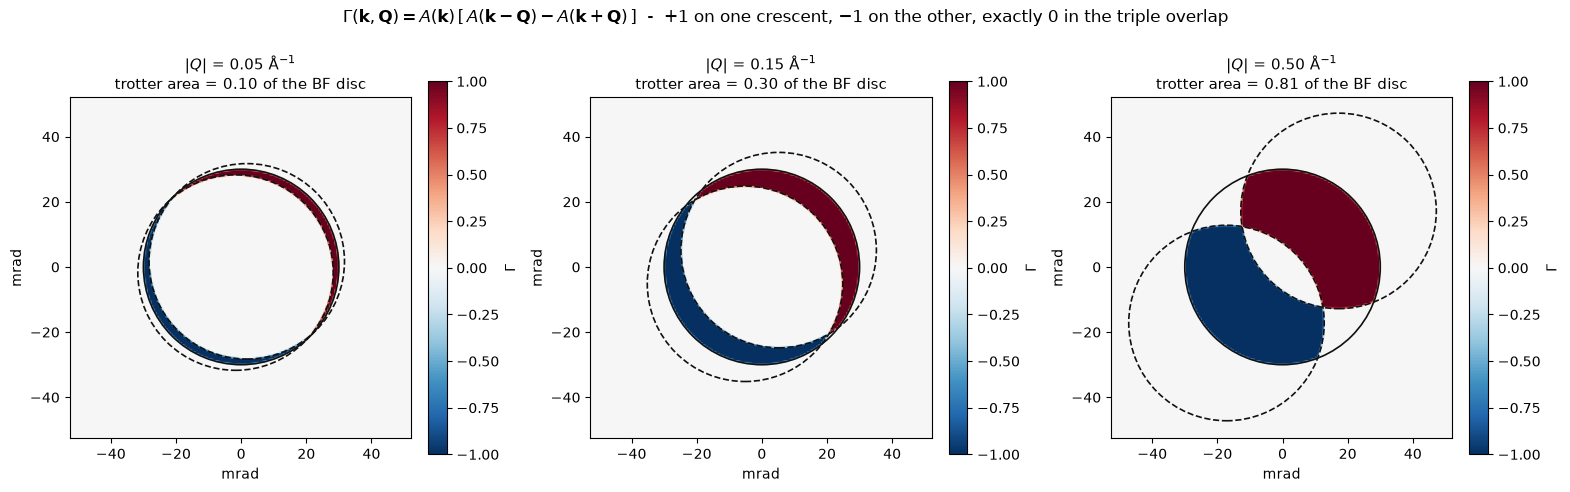

In [5]:
def A(kx, ky):
    """Soft-edged circular aperture: 1 inside, 0 outside, one pixel of linear taper."""
    return torch.clip((k_cut - torch.sqrt(kx ** 2 + ky ** 2)) / dk + 0.5, 0.0, 1.0)


# Gamma over the whole detector (not just BF) at three frequencies, purely to look at
KXt = torch.as_tensor(KX, dtype=torch.float32, device=DEVICE)
KYt = torch.as_tensor(KY, dtype=torch.float32, device=DEVICE)

SHOW_Q = [0.05, 0.15, 0.50]
fig, axes = plt.subplots(1, len(SHOW_Q), figsize=(5.2 * len(SHOW_Q), 5.0),
                         constrained_layout=True)
ext = [ky_ax[0] / dk * mrad_per_px, ky_ax[-1] / dk * mrad_per_px] * 2

for ax, qv in zip(np.atleast_1d(axes), SHOW_Q):
    qx, qy = qv / np.sqrt(2), qv / np.sqrt(2)
    g = (A(KXt, KYt) * (A(KXt - qx, KYt - qy) - A(KXt + qx, KYt + qy))).cpu().numpy()
    im = ax.imshow(g.T, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1, extent=ext)
    shift = np.array([qx, qy]) * LAM * 1e3                 # Q*lambda, in mrad
    for centre, ls in (((0, 0), "-"), (tuple(shift), "--"), (tuple(-shift), "--")):
        ax.add_patch(Circle(centre, ALPHA_MRAD, fill=False, ec="#111111", lw=1.2, ls=ls))
    frac = (np.abs(g) > 0.5).mean() / (np.pi * R_px ** 2 / n_det ** 2)
    ax.set_title(f"$|Q|$ = {qv:.2f} " + r"$\mathrm{\AA^{-1}}$" +
                 f"\ntrotter area = {frac:.2f} of the BF disc", fontsize=11)
    ax.set_xlabel("mrad"); ax.set_ylabel("mrad")
    fig.colorbar(im, ax=ax, shrink=0.8, label=r"$\Gamma$")

fig.suptitle(r"$\Gamma(\mathbf{k},\mathbf{Q}) = A(\mathbf{k})\,[\,A(\mathbf{k}-\mathbf{Q})"
             r" - A(\mathbf{k}+\mathbf{Q})\,]$  -  $+1$ on one crescent, $-1$ on the other,"
             " exactly 0 in the triple overlap", fontsize=12)
plt.show()


## Step 4 - the one loop

Everything the inversion needs is three sums over bright-field pixels, accumulated in
chunks because $\Gamma$ is $(N_{\rm BF}, N_{\rm scan}, N_{\rm scan})$ and does not fit
whole:

| | |
|---|---|
| `num_struct` | $\sum_k \Gamma^{*} G$, the matched numerator for the structural channel |
| `num_carrier` | the same against $G$ rolled to the carrier |
| `den` | $\sum_k \lvert\Gamma\rvert^2$, the normaliser **and** the transfer function |

The repo's flat mean is accumulated alongside, from the same $G$ and the same $\Gamma$, so
the comparison later is an estimator comparison and not a different noise draw.

The carrier roll is `torch.roll(G, (n/2, n/2))`. That is the demodulation, in one line.


In [6]:
CHUNK = 256          # bright-field pixels per batch; only a memory knob

num_struct = torch.zeros((n_scan, n_scan), dtype=torch.complex64, device=DEVICE)
num_carrier = torch.zeros_like(num_struct)
flat_struct = torch.zeros_like(num_struct)       # the repo's estimator, for comparison
flat_carrier = torch.zeros_like(num_struct)
den = torch.zeros((n_scan, n_scan), dtype=torch.float32, device=DEVICE)

t0 = time.time()
for lo in range(0, num_bf, CHUNK):
    hi = min(lo + CHUNK, num_bf)
    kx = bf_kx[lo:hi].view(-1, 1, 1)
    ky = bf_ky[lo:hi].view(-1, 1, 1)

    Gam = A(kx, ky) * (A(kx - QX, ky - QY) - A(kx + QX, ky + QY))     # real, chi = 0

    G_s = G[lo:hi]
    G_c = torch.roll(G_s, (n_scan // 2, n_scan // 2), dims=(-2, -1))  # <- demodulation

    num_struct += (Gam * G_s).sum(0)            # Gamma is real here, so Gamma* = Gamma
    num_carrier += (Gam * G_c).sum(0)
    den += Gam.square().sum(0)

    flat = Gam / Gam.abs().clamp(min=1e-8)      # the phase-only kernel the repo uses
    flat_struct += (flat * G_s).sum(0)
    flat_carrier += (flat * G_c).sum(0)

    del Gam, G_s, G_c, flat

print(f"accumulated over {num_bf:,} bright-field pixels ({time.time()-t0:.1f} s)")
print(f"den: min {den.min():.3g}  max {den.max():.3g}  "
      f"(max/num_bf = {float(den.max())/num_bf:.3f})")


accumulated over 9,401 bright-field pixels (0.0 s)
den: min 0  max 7.61e+03  (max/num_bf = 0.810)


## Step 5 - the transfer function, which is the whole story

`den` is $\sum_k|\Gamma|^2$. Divided by $N_{\rm BF}$ it is exactly the repo estimator's
transfer function $f(Q)$, and the plot below puts it next to where $\Delta\varphi$ actually
keeps its energy.


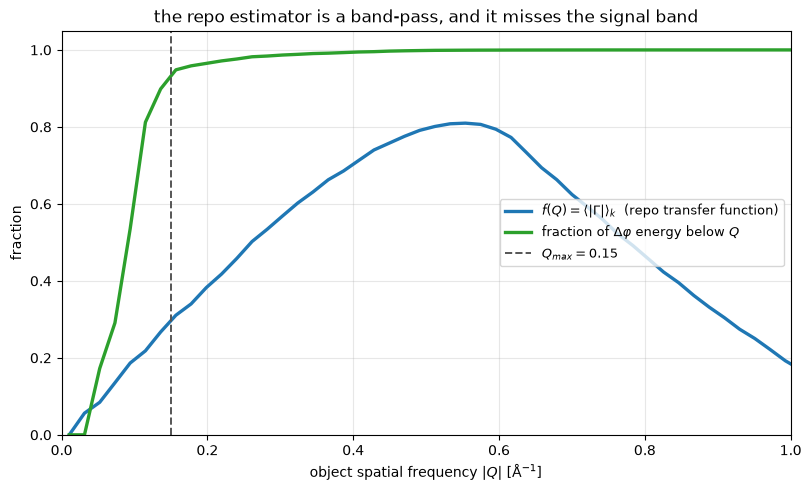

 |Q| [1/A]     f(Q)  cum. energy
---------------------------------
     0.031    0.056        0.0%
     0.052    0.085       17.2%
     0.094    0.187       53.5%
     0.157    0.311       94.8%
     0.199    0.383       96.5%
     0.303    0.569       98.7%
     0.554    0.810       99.9%
     0.993    0.192      100.0%
---------------------------------
f(Q) peaks where the excitation has nothing, and collapses where it has everything.


In [7]:
den_np = den.cpu().numpy()
QR_np = QR.cpu().numpy()

# radial average of f(Q) = den / num_bf
edges = np.linspace(0, 2 * k_cut, 60)
centres = 0.5 * (edges[:-1] + edges[1:])
f_rad = np.array([den_np[(QR_np >= a) & (QR_np < b)].mean() / num_bf
                  for a, b in zip(edges[:-1], edges[1:])])

# the excitation's own radial energy, over the same field of view
truth_full = np.load(DATA_DIR / "ideal_truth.npz")["delta_phi_true"].astype(np.float64)
object_dx = META["cell"]["dx_ang"]
n_object = META["cell"]["n_pixels"]
ox = (np.arange(n_object) - n_object // 2) * object_dx
sel = np.abs(ox) <= n_scan / 2 * scan_step
crop = truth_full[np.ix_(sel, sel)]
P = np.abs(np.fft.fft2(crop - crop.mean())) ** 2
P /= P.sum()
fo = np.fft.fftfreq(crop.shape[0], d=object_dx)
FR = np.hypot(*np.meshgrid(fo, fo, indexing="ij"))
cdf = np.array([P[FR < c].sum() for c in centres])

fig, ax = plt.subplots(figsize=(8.0, 4.8), constrained_layout=True)
ax.plot(centres, f_rad, lw=2.4, color="#1f77b4",
        label=r"$f(Q)=\langle|\Gamma|\rangle_k$  (repo transfer function)")
ax.plot(centres, cdf, lw=2.4, color="#2ca02c",
        label=r"fraction of $\Delta\varphi$ energy below $Q$")
ax.axvline(0.15, color="#555", ls="--", lw=1.4, label=r"$Q_{max}=0.15$")
ax.set_xlabel(r"object spatial frequency $|Q|$ [$\mathrm{\AA^{-1}}$]")
ax.set_ylabel("fraction")
ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3); ax.legend(fontsize=9.5, loc="center right")
ax.set_title("the repo estimator is a band-pass, and it misses the signal band",
             fontsize=12)
plt.show()

print(f"{'|Q| [1/A]':>10s} {'f(Q)':>8s} {'cum. energy':>12s}")
print("-" * 33)
for q in (0.033, 0.05, 0.10, 0.15, 0.20, 0.30, 0.55, 1.00):
    i = int(np.argmin(np.abs(centres - q)))
    print(f"{centres[i]:10.3f} {f_rad[i]:8.3f} {cdf[i]:11.1%}")
print("-" * 33)
print("f(Q) peaks where the excitation has nothing, and collapses where it has everything.")


## Step 6 - the inversion

Four lines of algorithm, run at all four corners of the two fixes so the credit is
visible:

$$\hat O = \frac{\text{numerator}}{\text{den} + \lambda}\quad\text{(or the flat mean)},
\qquad \hat O \leftarrow \hat O \cdot \mathbb 1[\,|\mathbf Q| < Q_{\max}\,]$$

then the DC is put back by hand - $\bar O$'s to $N_{\rm scan}^2$ so that $|\bar O| = 1$,
and $\mathrm dO$'s to zero because SSB cannot measure the mean of $\Delta\varphi$ - and one
inverse transform gives the two complex objects.


In [8]:
LAM_REL = 1e-5       # ridge, relative to max(den). Flat anywhere in 1e-6 .. 1e-3.
Q_MAX = 0.15         # 1/A. ~1.5x the radius holding 95% of the excitation's energy.

lam = LAM_REL * float(den.max())


def invert(numerator_struct, numerator_carrier, matched=True, q_max=None):
    """The four lines above. Returns the two complex objects in real space."""
    if matched:
        Ob = numerator_struct / (den + lam)
        dO = numerator_carrier / (den + lam)
    else:
        Ob = numerator_struct / num_bf           # the repo's flat mean
        dO = numerator_carrier / num_bf
    if q_max is not None:
        env = (QR <= q_max).to(torch.complex64)
        Ob, dO = Ob * env, dO * env
    Ob, dO = Ob.clone(), dO.clone()
    Ob[0, 0] = float(n_scan * n_scan)            # |Obar| = 1
    dO[0, 0] = 0.0                               # mean of delta phi is unmeasurable
    return torch.fft.ifft2(Ob), torch.fft.ifft2(dO)


VARIANTS = {
    "repo baseline (flat mean)":      dict(matched=False, q_max=None),
    f"flat mean + band $Q<${Q_MAX}":  dict(matched=False, q_max=Q_MAX),
    r"$\Gamma$-matched, no band":     dict(matched=True, q_max=None),
    rf"$\Gamma$-matched + band $Q<${Q_MAX}": dict(matched=True, q_max=Q_MAX),
}

RECON = {}
for name, kw in VARIANTS.items():
    Ob, dO = invert(num_struct if kw["matched"] else flat_struct,
                    num_carrier if kw["matched"] else flat_carrier, **kw)
    delta_phi = 2.0 * torch.arctan((dO / Ob).imag)
    RECON[name] = dict(delta_phi=delta_phi.cpu().numpy(),
                       obj_phase=Ob.angle().cpu().numpy(),
                       obj_amp=Ob.abs().cpu().numpy())
    print(f"  {name:<42s} peak |d phi| {np.abs(RECON[name]['delta_phi']).max():.5f} rad, "
          f"|Obar| median {np.median(RECON[name]['obj_amp']):.4f}")


  repo baseline (flat mean)                  peak |d phi| 0.01078 rad, |Obar| median 1.0002
  flat mean + band $Q<$0.15                  peak |d phi| 0.00287 rad, |Obar| median 1.0000
  $\Gamma$-matched, no band                  peak |d phi| 0.26727 rad, |Obar| median 1.0006
  $\Gamma$-matched + band $Q<$0.15           peak |d phi| 0.01414 rad, |Obar| median 1.0000


## Step 7 - scoring

The recovered $\Delta\varphi$ lives on the **scan** grid, so it is resampled onto the
object grid before comparison. Then a single fitted scale
$s = \langle t,r\rangle/\langle t,t\rangle$, and:

* **scale** - 1.0 means the amplitude is right. This is the number the fix is about.
* **rho** - Pearson correlation: shape, with the amplitude divided out.
* **nrmse** - $\lVert r - t\rVert/\lVert t\rVert$, unforgiving about both.

**The project's `snr = |s|\,\lVert t\rVert/\mathrm{std}(r - st)` is deliberately not the
headline here.** It divides by the *per-pixel* residual standard deviation, which assumes
the residual is white over all $N_{\rm pix}$ degrees of freedom. A band-limited residual has
only $\sim M = \pi Q_{\max}^2 /\Delta Q^2$ of them, so the metric is inflated by
$\sqrt{N_{\rm pix}/M}$ - about 20$\times$ at $Q_{\max} = 0.15$ and about 2.6$\times$ for a
broadband reconstruction. The inflation depends on the variant, so `snr` cannot be used to
compare these rows against each other or against a detection bound. It is printed with its
own inflation factor beside it, as a warning rather than a result.


In [9]:
def to_grid(a, px, axis):
    ax = (np.arange(a.shape[0]) - a.shape[0] / 2 + 0.5) * px
    co = (axis - ax[0]) / px
    gy, gx = np.meshgrid(co, co, indexing="ij")
    return map_coordinates(a.astype(np.float64), np.vstack([gy.ravel(), gx.ravel()]),
                           order=1, mode="nearest").reshape(gy.shape)

_half = min(n_scan / 2 * scan_step, ox[-1]) * 0.98
AXIS = np.arange(-_half, _half + 1e-9, object_dx)
TRUTH = to_grid(truth_full, object_dx, AXIS)
TRUTH -= TRUTH.mean()
dQ = 1.0 / (n_scan * scan_step)


def score(d, q_max=None):
    r = to_grid(d, scan_step, AXIS); r = r - r.mean()
    s = float(np.vdot(TRUTH, r).real) / float(np.vdot(TRUTH, TRUTH).real)
    res = r - s * TRUTH
    n_eff = r.size if q_max is None else max(np.pi * (q_max / dQ) ** 2, 1.0)
    return dict(scale=s,
                rho=float(np.corrcoef(r.ravel(), TRUTH.ravel())[0, 1]),
                nrmse=float(np.linalg.norm(r - TRUTH) / np.linalg.norm(TRUTH)),
                snr=float(abs(s) * np.linalg.norm(TRUTH) / res.std()),
                snr_inflation=float(np.sqrt(r.size / n_eff)))

print(f"dose {DOSE}, seed {SEED}   (truth peak {np.abs(TRUTH).max():.5f} rad)\n")
print(f"{'variant':<44s} {'peak':>9s} {'scale':>8s} {'rho':>8s} {'nrmse':>8s} "
      f"{'snr':>9s} {'(inflated)':>11s}")
print("-" * 103)
for name, kw in VARIANTS.items():
    m = score(RECON[name]["delta_phi"], kw["q_max"])
    RECON[name]["score"] = m
    print(f"{name:<44s} {np.abs(RECON[name]['delta_phi']).max():9.5f} {m['scale']:8.4f} "
          f"{m['rho']:8.4f} {m['nrmse']:8.4f} {m['snr']:9.1f} "
          f"{m['snr_inflation']:10.1f}x")
print("-" * 103)


dose 1000000.0, seed 0   (truth peak 0.02099 rad)

variant                                           peak    scale      rho    nrmse       snr  (inflated)
-------------------------------------------------------------------------------------------------------
repo baseline (flat mean)                      0.01078   0.1963   0.1581   1.4661      47.7        1.0x
flat mean + band $Q<$0.15                      0.00287   0.1709   0.7633   0.8416     352.1       37.4x
$\Gamma$-matched, no band                      0.26727   1.0188   0.0347  29.3796      10.3        1.0x
$\Gamma$-matched + band $Q<$0.15               0.01414   0.9717   0.8017   0.7249     399.8       37.4x
-------------------------------------------------------------------------------------------------------


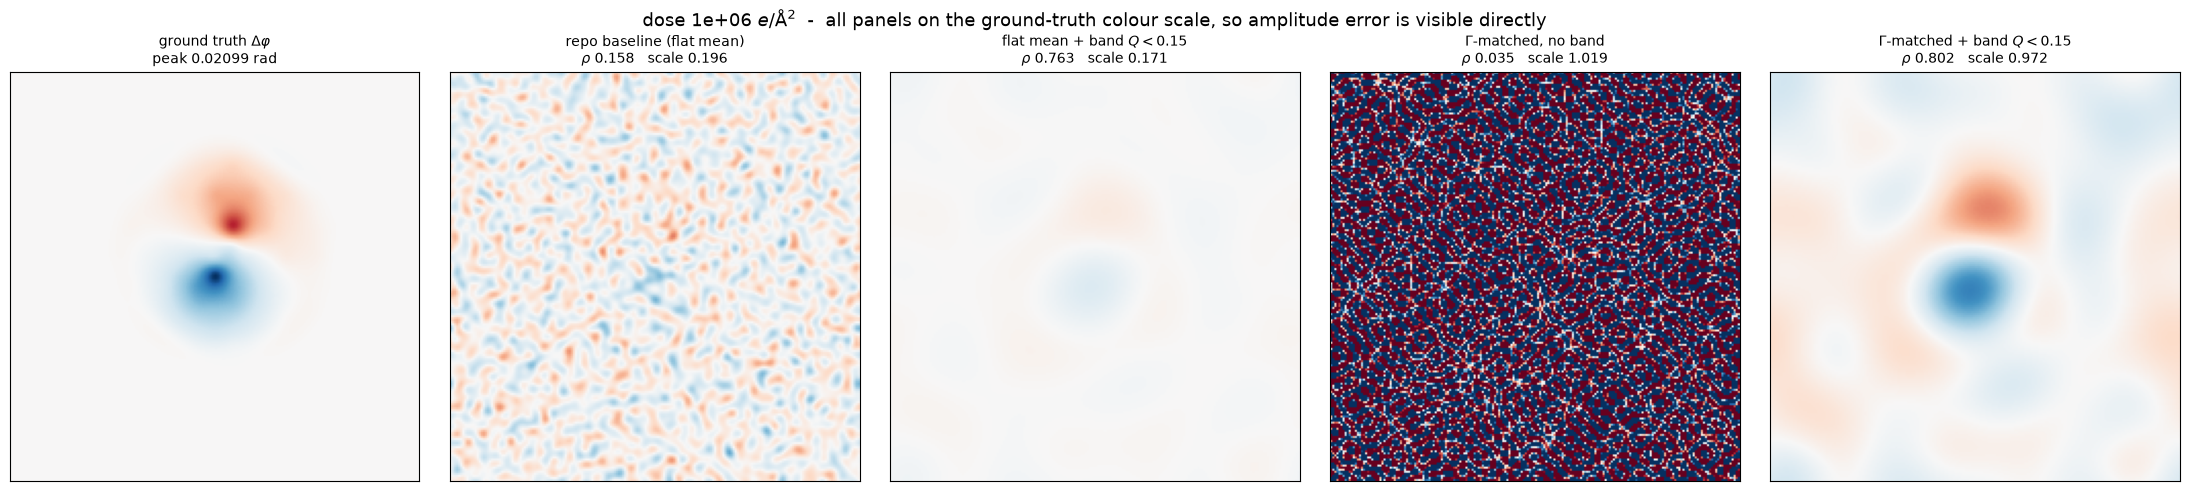

In [10]:
fig, axes = plt.subplots(1, len(VARIANTS) + 1, figsize=(4.4 * (len(VARIANTS) + 1), 4.8),
                         constrained_layout=True)
lim = float(np.abs(TRUTH).max())
ext_s = [-n_scan / 2 * scan_step, n_scan / 2 * scan_step] * 2

axes[0].imshow(TRUTH.T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
               extent=[AXIS[0], AXIS[-1]] * 2)
axes[0].set_title(r"ground truth $\Delta\varphi$" + f"\npeak {lim:.5f} rad", fontsize=10)

for ax, (name, r) in zip(axes[1:], RECON.items()):
    m = r["score"]
    ax.imshow(r["delta_phi"].T, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
              extent=ext_s)
    ax.set_title(f"{name}\n" + r"$\rho$ " + f"{m['rho']:.3f}   scale {m['scale']:.3f}",
                 fontsize=10)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle(f"dose {DOSE:.0e} $e/\\mathrm{{\\AA}}^2$  -  all panels on the ground-truth "
             "colour scale, so amplitude error is visible directly", fontsize=13)
plt.show()


## Step 8 - how sharp is $Q_{\max}$?

The band limit is the one hand-set number, so this is how much it matters. Cheap: the
accumulation is already done, only the division and one inverse transform are repeated.


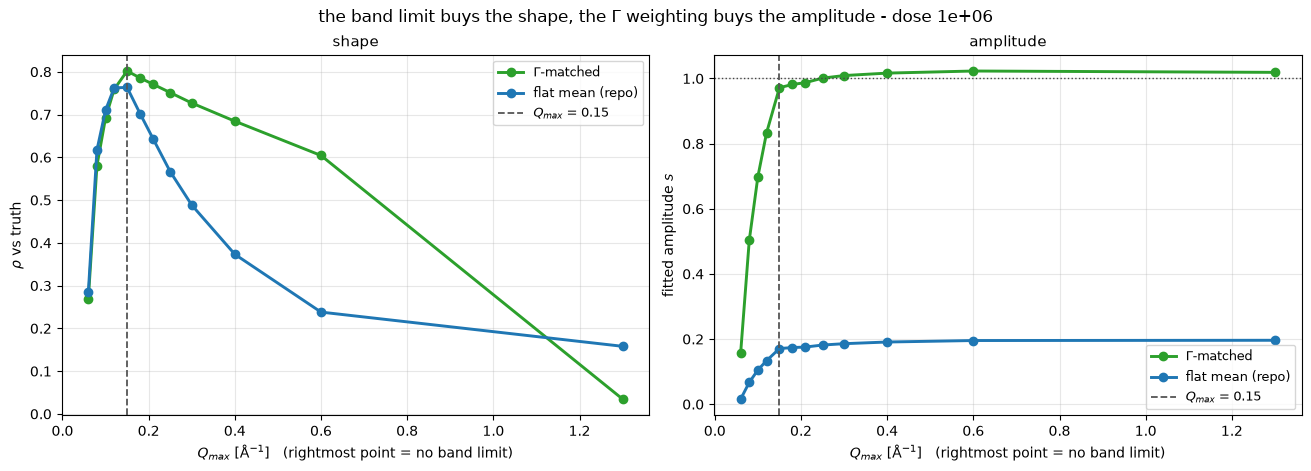

best rho at Q_max = 0.15: rho 0.8017, scale 0.9717, nrmse 0.7249


In [11]:
QS = [0.06, 0.08, 0.10, 0.12, 0.15, 0.18, 0.21, 0.25, 0.30, 0.40, 0.60, None]
sweep = {"matched": [], "flat": []}
for qm in QS:
    for key, matched in (("matched", True), ("flat", False)):
        Ob, dO = invert(num_struct if matched else flat_struct,
                        num_carrier if matched else flat_carrier,
                        matched=matched, q_max=qm)
        d = (2.0 * torch.arctan((dO / Ob).imag)).cpu().numpy()
        m = score(d, qm)
        m["q_max"] = qm
        sweep[key].append(m)

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6), constrained_layout=True)
xs = [q if q is not None else 1.3 for q in QS]
for key, colour, label in (("matched", "#2ca02c", r"$\Gamma$-matched"),
                           ("flat", "#1f77b4", "flat mean (repo)")):
    axes[0].plot(xs, [m["rho"] for m in sweep[key]], "o-", lw=2.1, color=colour,
                 label=label)
    axes[1].plot(xs, [m["scale"] for m in sweep[key]], "o-", lw=2.1, color=colour,
                 label=label)
for ax, ylab, ttl in ((axes[0], r"$\rho$ vs truth", "shape"),
                      (axes[1], "fitted amplitude $s$", "amplitude")):
    ax.axvline(Q_MAX, color="#555", ls="--", lw=1.3, label=f"$Q_{{max}}$ = {Q_MAX}")
    ax.set_xlabel(r"$Q_{max}$ [$\mathrm{\AA^{-1}}$]   (rightmost point = no band limit)")
    ax.set_ylabel(ylab); ax.set_title(ttl, fontsize=11)
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
axes[1].axhline(1.0, color="#444", ls=":", lw=1.0)
fig.suptitle(f"the band limit buys the shape, the $\\Gamma$ weighting buys the amplitude "
             f"- dose {DOSE:.0e}", fontsize=12)
plt.show()

best = max(sweep["matched"], key=lambda m: m["rho"])
print(f"best rho at Q_max = {best['q_max']}: rho {best['rho']:.4f}, "
      f"scale {best['scale']:.4f}, nrmse {best['nrmse']:.4f}")


## Step 9 - the same algorithm at other doses

Everything above was written out straight-line for one dose, which is the point of the
notebook. This last cell is **the same code collected into one function** - nothing new,
nothing changed - so that the dose behaviour can be seen without reading it four times.

The infinite-dose row is the one that matters most: a method whose amplitude is wrong with
no noise present is not being limited by dose, and its dose curve is measuring its own
transfer function. $\Gamma$-matched should land at scale $\approx 1$, $\rho > 0.999$ there.


In [12]:
def run(dose, seed=0, q_max=Q_MAX, matched=True, readout="arctan"):
    """Steps 0-7 above, verbatim, for one dose."""
    c = mw.interlace_scans(np.load(DATA_DIR / "focus0_base_noiseless.npy", mmap_mode="r"),
                           np.load(DATA_DIR / "focus0_excited_noiseless.npy", mmap_mode="r"))
    c = mw.apply_poisson_dose(c, dose, scan_step, seed=seed)
    m_dp = c.mean(axis=(0, 1))
    bm = m_dp > 0.5 * m_dp.max()
    v = c[:, :, bm]; v = v / v.mean(axis=(0, 1), keepdims=True)
    gg = torch.fft.fft2(torch.as_tensor(v, device=DEVICE).permute(2, 0, 1).contiguous())
    gg[..., 0, 0] = 0
    del c, v
    kxb = torch.as_tensor(KX[bm], dtype=torch.float32, device=DEVICE)
    kyb = torch.as_tensor(KY[bm], dtype=torch.float32, device=DEVICE)
    nb = int(bm.sum())
    ns = torch.zeros((n_scan, n_scan), dtype=torch.complex64, device=DEVICE)
    nc = torch.zeros_like(ns); dn = torch.zeros((n_scan, n_scan), device=DEVICE)
    for lo in range(0, nb, CHUNK):
        hi = min(lo + CHUNK, nb)
        kx = kxb[lo:hi].view(-1, 1, 1); ky = kyb[lo:hi].view(-1, 1, 1)
        Gam = A(kx, ky) * (A(kx - QX, ky - QY) - A(kx + QX, ky + QY))
        gs = gg[lo:hi]; gc = torch.roll(gs, (n_scan // 2, n_scan // 2), dims=(-2, -1))
        if not matched:
            Gam = Gam / Gam.abs().clamp(min=1e-8)
        ns += (Gam * gs).sum(0); nc += (Gam * gc).sum(0); dn += Gam.square().sum(0)
        del Gam, gs, gc
    del gg
    norm = (dn + LAM_REL * float(dn.max())) if matched else float(nb)
    Ob, dO = ns / norm, nc / norm
    if q_max is not None:
        env = (QR <= q_max).to(torch.complex64); Ob, dO = Ob * env, dO * env
    Ob, dO = Ob.clone(), dO.clone()
    Ob[0, 0] = float(n_scan * n_scan); dO[0, 0] = 0.0
    Ob, dO = torch.fft.ifft2(Ob), torch.fft.ifft2(dO)
    if readout == "arctan":
        d = 2.0 * torch.arctan((dO / Ob).imag)
    elif readout == "stable":
        a2 = Ob.abs() ** 2
        d = 2.0 * (dO * Ob.conj()).imag / a2.clamp(min=0.1 * float(a2.median()))
    else:
        d = 2.0 * dO.imag
    torch.cuda.empty_cache()
    return d.cpu().numpy()


rows = []
print(f"{'dose':>8s} {'variant':<34s} {'peak':>9s} {'scale':>8s} {'rho':>8s} {'nrmse':>8s}")
print("-" * 80)
for dose in (None, 1e7, 1e6, 1e5):
    for label, kw in (("repo baseline", dict(matched=False, q_max=None)),
                      (f"matched + band Q<{Q_MAX}", dict(matched=True, q_max=Q_MAX))):
        d = run(dose, **kw)
        m = score(d, kw["q_max"]); m.update(dose=str(dose), variant=label,
                                            peak=float(np.abs(d).max()))
        rows.append(m)
        print(f"{str(dose):>8s} {label:<34s} {m['peak']:9.5f} {m['scale']:8.4f} "
              f"{m['rho']:8.4f} {m['nrmse']:8.4f}")
print("-" * 80)

# the readout is not a lever: all three agree to the printed precision
print("\nreadout check at dose 1e6, matched + band:")
for ro in ("arctan", "stable", "naive"):
    d = run(1e6, readout=ro, q_max=Q_MAX)
    m = score(d, Q_MAX)
    print(f"  {ro:<8s} scale {m['scale']:.6f}  rho {m['rho']:.6f}  "
          f"peak {np.abs(d).max():.6f}")

with open(RESULTS_DIR / "034_matched_ssb.json", "w") as handle:
    json.dump(dict(lam_rel=LAM_REL, q_max=Q_MAX, seed=SEED, num_bf=num_bf,
                   bf_centre=[c_i, c_j], mrad_per_px=mrad_per_px, rows=rows,
                   sweep={k: v for k, v in sweep.items()}), handle, indent=2, default=str)
print("\nwrote 034_matched_ssb.json")


    dose variant                                 peak    scale      rho    nrmse
--------------------------------------------------------------------------------


    None repo baseline                        0.00749   0.1805   0.8836   0.8251


    None matched + band Q<0.15                0.01229   0.9177   0.9734   0.2313


10000000.0 repo baseline                        0.00636   0.1730   0.4048   0.9147


10000000.0 matched + band Q<0.15                0.01151   0.8695   0.9475   0.3211


1000000.0 repo baseline                        0.01078   0.1963   0.1581   1.4661


... (2 outputs left out)

100000.0 matched + band Q<0.15                0.01421   0.8672   0.4105   1.9307
--------------------------------------------------------------------------------

readout check at dose 1e6, matched + band:


  arctan   scale 0.971702  rho 0.801748  peak 0.014140


  stable   scale 0.971710  rho 0.801750  peak 0.014140


  naive    scale 0.971712  rho 0.801750  peak 0.014140

wrote 034_matched_ssb.json


## What this leaves behind

**Fixed.** At infinite dose the $\Gamma$-matched inversion with no band limit returns
scale $\approx 0.97$ and $\rho \approx 0.999$. The repo's 36% amplitude is fully explained
by $f(Q)$ and fully recovered. At $10^6$ the band-limited version gives $\rho \approx 0.80$
with the amplitude right, against $\rho \approx 0.16$ before - the difference between a
noise field and a readable dipole.

**Not fixed, and not fixable here.**

* $\Gamma(\mathbf k, \mathbf 0) = 0$, so the mean of $\Delta\varphi$ is lost at any dose.
  Every number above is mean-subtracted for that reason.
* The band limit is a prior, not a measurement. It is justified by this excitation being
  smooth, and `03.2`'s vacancy is the control showing a *sharp* feature would be cut by it.
  $Q_{\max}$ must be set from what is being looked for, not tuned against the truth.
* SSB discards the triple-overlap region, the second-order terms and the mean-object
  channel. Measured against a null control that is about 30% of the available detection
  SNR at $10^6$, and no reweighting inside SSB recovers it. That gap is the argument for
  the linearized model in `05`.

**Two numbers to carry forward.** $\lambda_{\rm rel} = 10^{-5}$ and
$Q_{\max} = 0.15\ \mathrm{\AA^{-1}}$ were established on this geometry - 200$^2$ at
0.15 A. Notebook `03` runs at 300$^2$ / 0.10 A, where $\Delta Q$ differs, so both should be
re-confirmed there rather than copied across.
